#### Import Libraries

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
import warnings
warnings.filterwarnings("ignore")

#### Loading or display dataset

In [52]:
df = pd.read_csv("data.csv")
df.head(3)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350


#### 2 Door Car info

In [53]:
precious_car = df[df["Number of Doors"] == 2]

# Calculate average MSRP of 2-door cars
avg_price = precious_car["MSRP"].mean()
max_price = precious_car["MSRP"].max()
min_price = precious_car["MSRP"].min()
print("Max Price of 2-door cars: ", max_price)
print("Minimum Price of 2-door cars: ", min_price)
print("Average MSRP of 2-door cars:", avg_price)

Max Price of 2-door cars:  2065902
Minimum Price of 2-door cars:  2000
Average MSRP of 2-door cars: 54556.08196202532


#### Extracting info of Premium cars

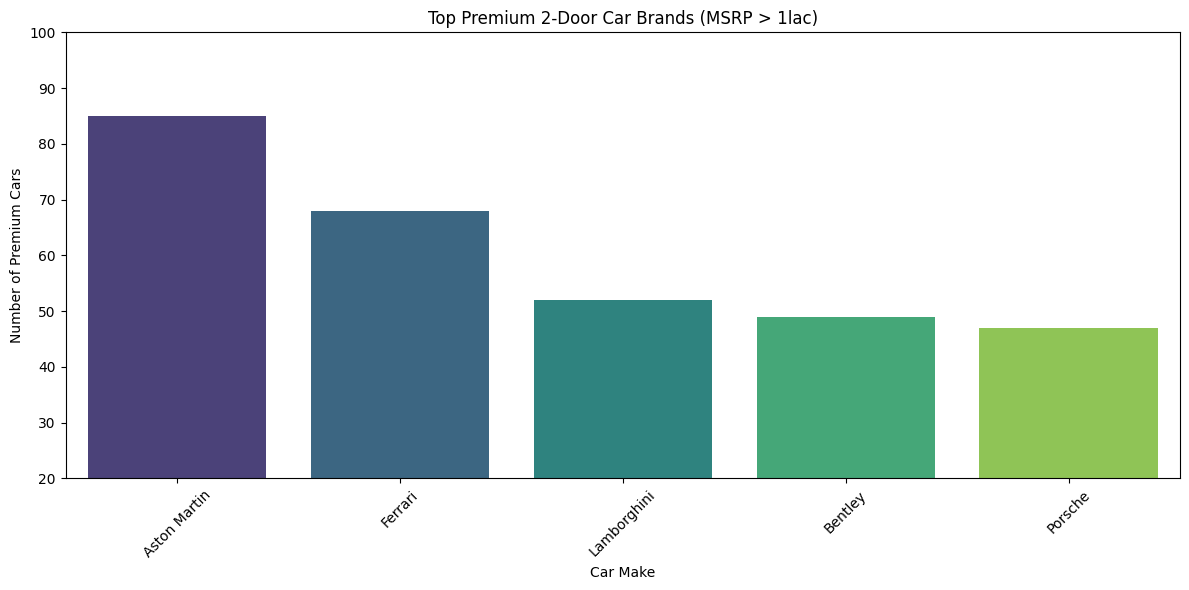

Make
Aston Martin     85
Ferrari          68
Lamborghini      52
Bentley          49
Porsche          47
Mercedes-Benz    47
Audi             25
Maserati         20
Rolls-Royce      11
BMW              11
Nissan            8
Dodge             7
McLaren           5
Spyker            3
Bugatti           3
Ford              2
Cadillac          2
Lexus             1
Acura             1
Name: count, dtype: int64

In [54]:

# Select premium 2-door cars (MSRP > 1 lac)
premium_cars = precious_car[precious_car["MSRP"] > 100000]


# Count of premium cars by Make (top 5)
make_counts = premium_cars["Make"].value_counts().reset_index()[:5]
make_counts.columns = ["Make", "Count"]


plt.figure(figsize=(12,6))
sns.barplot(x="Make", y="Count", data=make_counts, palette="viridis")
plt.title("Top Premium 2-Door Car Brands (MSRP > 1lac)")
plt.xlabel("Car Make")
plt.ylabel("Number of Premium Cars")
plt.ylim(20,100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

premium_cars["Make"].value_counts()


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

#### Checking Null values

Market Category      31.4084
Engine HP             0.5792
Engine Cylinders      0.2518
Number of Doors       0.0504
Engine Fuel Type      0.0252
Make                  0.0000
Model                 0.0000
Year                  0.0000
Transmission Type     0.0000
Driven_Wheels         0.0000
Vehicle Size          0.0000
Vehicle Style         0.0000
highway MPG           0.0000
city mpg              0.0000
Popularity            0.0000
MSRP                  0.0000
dtype: float64


<Axes: >

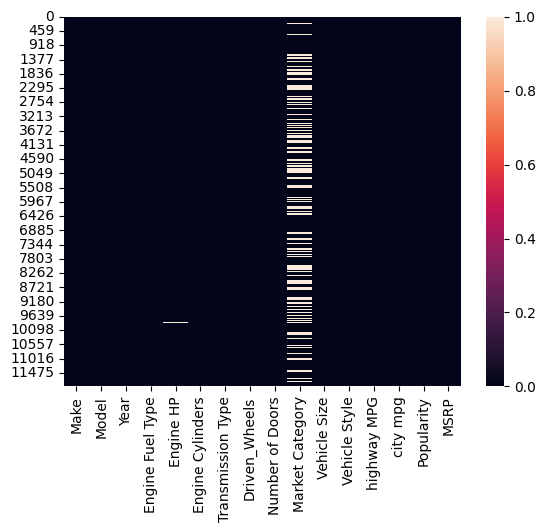

In [56]:
null_values = round(df.isnull().sum()/len(df)*100,4).sort_values(ascending=False)
print(null_values)
sns.heatmap(df.isnull())

#### Handling Null values

In [57]:
object_col = ["Market Category","Engine Fuel Type"]
for col in object_col:
    mode_value = df[col].mode()[0]  
    df[col].fillna(mode_value, inplace=True)
    
float_col = ["Engine HP","Engine Cylinders" ,"Number of Doors"]
for col in float_col:
    mean_value = df[col].mean() 
    df[col].fillna(mean_value, inplace=True)
    
df.isnull().sum()


Make                 0
Model                0
Year                 0
Engine Fuel Type     0
Engine HP            0
Engine Cylinders     0
Transmission Type    0
Driven_Wheels        0
Number of Doors      0
Market Category      0
Vehicle Size         0
Vehicle Style        0
highway MPG          0
city mpg             0
Popularity           0
MSRP                 0
dtype: int64

#### Analysis based on Types of car

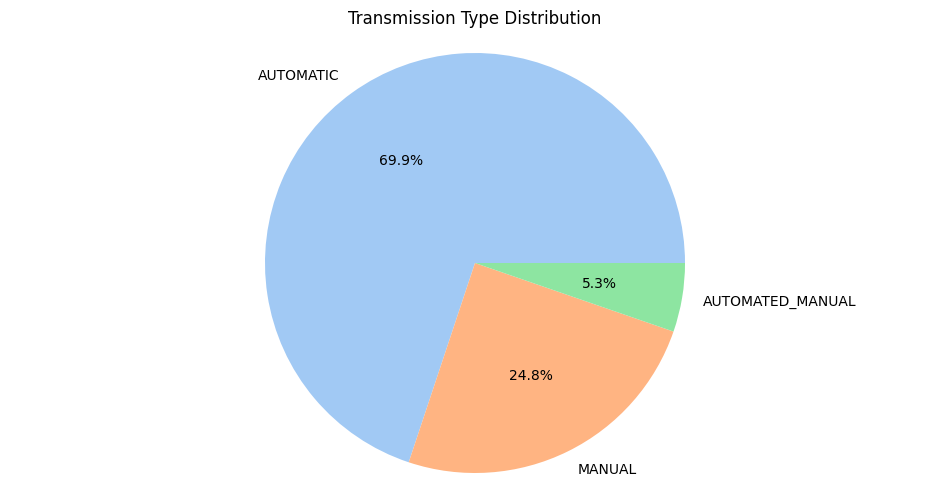

Transmission Type
AUTOMATIC           8266
MANUAL              2935
AUTOMATED_MANUAL     626
DIRECT_DRIVE          68
UNKNOWN               19
Name: count, dtype: int64

In [58]:
df.head()
transmission_counts = df["Transmission Type"].value_counts()[:3]

# Plot
plt.figure(figsize=(12, 6))
plt.pie(
    transmission_counts,
    labels=transmission_counts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette('pastel')
)
plt.title("Transmission Type Distribution")
plt.axis('equal')  
plt.show()
df["Transmission Type"].value_counts()

### Analysis Car category and merging first letter to overcome detail

Market Category
Crossover                                          4852
Flex Fuel                                           872
Luxury                                              855
Luxury,Performance                                  673
Hatchback                                           641
                                                   ... 
Crossover,Exotic,Luxury,Performance                   1
Exotic,Luxury,High-Performance,Hybrid                 1
Crossover,Exotic,Luxury,High-Performance              1
Flex Fuel,Factory Tuner,Luxury,High-Performance       1
Performance,Hybrid                                    1
Name: count, Length: 71, dtype: int64


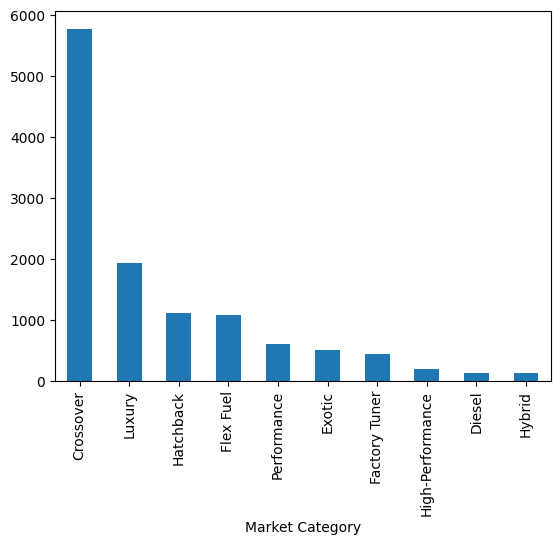

In [59]:
print(df["Market Category"].value_counts())
df["Market Category"] = df["Market Category"].apply(lambda x:" ".join(x.split(",")[:1]))
df["Market Category"].value_counts().plot(kind="bar")
plt.show()


In [60]:
df.head()


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Factory Tuner,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


### Max MPG of vehicles

In [61]:
df.groupby("Vehicle Style")[["highway MPG","city mpg"]].max()

,highway MPG,city mpg
Vehicle Style,,
2dr Hatchback,108,122
2dr SUV,30,22
4dr Hatchback,111,137
4dr SUV,74,78
Cargo Minivan,29,24
Cargo Van,20,15
Convertible,41,31
Convertible SUV,28,24
Coupe,41,31


#### combining some values of engine fuel coloumns

In [62]:
print(df["Engine Fuel Type"].value_counts())
df["Engine Fuel Type"]= df["Engine Fuel Type"].apply(lambda x :" ".join(x.split("(")[:1]))
df["Engine Fuel Type"].unique()

Engine Fuel Type
regular unleaded                                7175
premium unleaded (required)                     2009
premium unleaded (recommended)                  1523
flex-fuel (unleaded/E85)                         899
diesel                                           154
electric                                          66
flex-fuel (premium unleaded required/E85)         54
flex-fuel (premium unleaded recommended/E85)      26
flex-fuel (unleaded/natural gas)                   6
natural gas                                        2
Name: count, dtype: int64


array(['premium unleaded ', 'regular unleaded', 'flex-fuel ', 'diesel',
       'electric', 'natural gas'], dtype=object)

#### Wheel Car information

In [63]:
print(df["Driven_Wheels"].unique())
df["Driven_Wheels"] = df["Driven_Wheels"].apply(lambda x: x.split()[0].capitalize())
df["Driven_Wheels"].value_counts()


['rear wheel drive' 'front wheel drive' 'all wheel drive'
 'four wheel drive']


Driven_Wheels
Front    4787
Rear     3371
All      2353
Four     1403
Name: count, dtype: int64

#### Average price by engine fuel

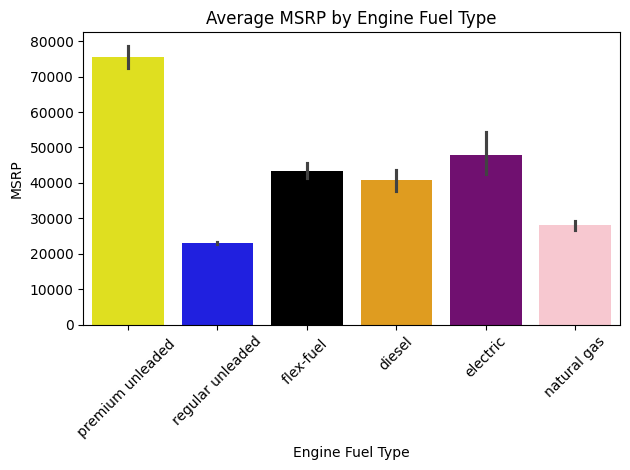

In [64]:
sns.barplot(
    data=df,
    x="Engine Fuel Type",
    y="MSRP",
    estimator='mean',
    palette=["yellow", "blue", "black", "orange","purple","pink"]  # Use palette instead of color
)

plt.xticks(rotation=45)
plt.title("Average MSRP by Engine Fuel Type")
plt.tight_layout()
plt.show()

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11914 non-null  object 
 4   Engine HP          11914 non-null  float64
 5   Engine Cylinders   11914 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11914 non-null  float64
 9   Market Category    11914 non-null  object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

##### Standarize or normalize data

In [66]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd


Object_columns = [
    'Make', 'Model', 'Engine Fuel Type', 'Transmission Type',
    'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style'
]


encoder = LabelEncoder()


for column in Object_columns:
    df[column] = encoder.fit_transform(df[[column]])
    
scaler = StandardScaler()
df[df.columns] = scaler.fit_transform(df[df.columns])

df.tail(3)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
11911,-1.596919,1.636483,0.213164,-0.358818,0.464900,0.208729,-0.487387,-1.659471,0.640035,-0.889882,1.180202,-1.293007,-0.41043,-0.415387,-0.936965,0.166791
11912,-1.596919,1.636483,0.345101,-0.358818,0.464900,0.208729,-0.487387,-1.659471,0.640035,-0.889882,1.180202,-1.293007,-0.41043,-0.415387,-0.936965,0.171783
11913,0.121864,1.640196,-0.578453,0.615198,-0.260732,0.208729,-0.487387,0.215440,0.640035,1.509791,1.180202,1.148467,-0.07193,-0.304120,-1.036147,-0.192986


#### Training or testing split

In [67]:
X = df.drop("MSRP", axis=1)
y = df["MSRP"]

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (9531, 15)
X_test shape: (2383, 15)
y_train shape: (9531,)
y_test shape: (2383,)


#### Appling different regression model by zip file and getting result based on r2 result

In [69]:


models = [
    LinearRegression(),
    Ridge(),  # Regularized linear regression
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    KNeighborsRegressor()
]

model_names = [
    "Linear Regression",
    "Ridge Regression",
    "Decision Tree Regressor",
    "Random Forest Regressor",
    "K Neighbors Regressor"
]



model_score = []

for model, name in zip(models, model_names):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    model_score.append([name, r2])

results_df = pd.DataFrame(model_score, columns=["Model", "R2 Score"])
print(results_df)



                     Model  R2 Score
0        Linear Regression  0.584628
1         Ridge Regression  0.584647
2  Decision Tree Regressor  0.972160
3  Random Forest Regressor  0.974344
4    K Neighbors Regressor  0.927334


#### Best model with best r2 score

In [70]:
best_model = sorted(model_score, key=lambda x: x[1], reverse=True)
print(f"Overall best model for predicting the MRSP IS : {best_model[0][0]}")
print(f"Best model R2 score: {best_model[0][1]}")

Overall best model for predicting the MRSP IS : Random Forest Regressor
Best model R2 score: 0.9743444616611624


#### Top three model based on r2 score

In [71]:
top_three = best_model[:3]

# Separate model names and scores
top_three_models = [model[0] for model in top_three]
top_three_scores = [round(model[1], 4) for model in top_three]

# Print
# Format scores as percentages
formatted_scores = [f"{score * 100:.2f}%" for score in top_three_scores]

print(f"Top three models are {', '.join(top_three_models)},\nwith scores {formatted_scores}")



Top three models are Random Forest Regressor, Decision Tree Regressor, K Neighbors Regressor,
with scores ['97.43%', '97.22%', '92.73%']


#### Getting pie plot of top 3 models based on r2 score

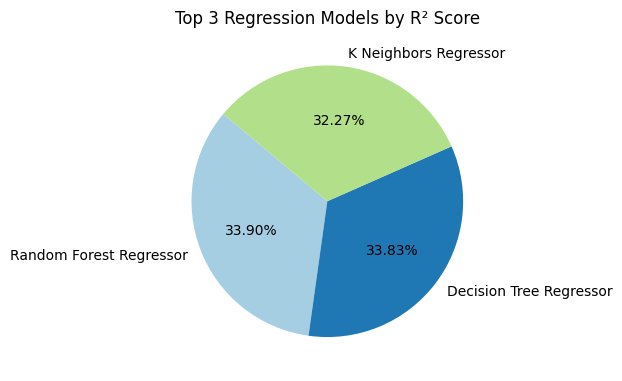

In [72]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 6))
plt.pie(
    top_three_scores,                      # Values
    labels=top_three_models,              # Labels
    autopct='%1.2f%%',                    # Show percentage
    startangle=140,                       # Rotate for better view
    colors=plt.cm.Paired.colors[:3]       # Optional color palette
)
plt.title('Top 3 Regression Models by R² Score')
plt.tight_layout()
plt.show()


#### Applying different error metrics on regression model

In [73]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

metrics_result = []

for model, name in zip(models, model_names):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    metrics_result.append([name, round(mse, 4), round(mae, 4), round(rmse, 4)])

# Create DataFrame to display results
metrics_df = pd.DataFrame(metrics_result, columns=["Model", "MSE", "MAE", "RMSE"])
print(metrics_df)


                     Model     MSE     MAE    RMSE
0        Linear Regression  0.2740  0.3309  0.5235
1         Ridge Regression  0.2740  0.3308  0.5235
2  Decision Tree Regressor  0.0176  0.0525  0.1328
3  Random Forest Regressor  0.0185  0.0521  0.1361
4    K Neighbors Regressor  0.0479  0.0767  0.2190


#### Minimum MSE or Maximum MSE

In [74]:
minimum_mse = np.min(metrics_df['MSE'])
maximum_mse = np.max(metrics_df['MSE'])
print('Minimum MSE:', minimum_mse)
print('Maximum MSE:', maximum_mse)


Minimum MSE: 0.0176
Maximum MSE: 0.274
